# 02. Demand Forecasting

**Task:** forecast next week's units for every store × product.
**Role in the pricing system:** the forecast gives the *level* of demand at the current price (baseline demand `Q0`).
The elasticity in notebook 03 gives the *slope* (how demand changes with price).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from src import config
R = config.RESULTS_DIR
%matplotlib inline

## 1. Feature engineering (`src/feature_engineering.py`)
The data is **weekly**, so the lag set is weekly: 1, 2, 3, 4, 8, 13, 52 weeks. Daily-style lags (7/14/28 days) would be
meaningless here. The table below lists every feature family and why it helps.

| family | features | why |
|---|---|---|
| demand history | lags 1-4, 8, 13, 52; rolling mean 4/8/13; rolling std 8; expanding mean | persistence, level, volatility, same-week-last-year |
| availability | `weeks_observed_last_13` | proxy for ranging / stockouts |
| price & promo (target week) | price, base price, discount %, log price, feature, display, TPR, price vs recent regular price | the decision variables; known in advance |
| promo history | discount / feature / display last week | pantry loading → post-promotion dip |
| calendar | week of year, month, quarter, year, holiday, Thanksgiving, Christmas, Super Bowl | seasonality and events |
| store / product | store, UPC, category, sub-category, manufacturer, segment, state, size, baskets | cross-sectional level differences |

**Leakage rules**
* Every history feature is computed on a complete weekly calendar and **shifted by ≥ 1 week**.
* Same-week outcomes (`visits`, `hhs`, `spend`) are **never** features: they are only known after the week and are mechanically tied to units.
* Target-week price and promotion **are** features, because a retailer plans them in advance. This is also what lets us ask "*what if price = P?*".

In [2]:
from src import feature_engineering as fe, forecasting as fc, evaluation as ev, visualization as viz
df = pd.read_parquet(config.FEATURES_FILE)
df = fe.apply_category_levels(df)
print(df.shape, "| features:", len(fe.feature_columns()))
print("share of grid weeks with recorded sales:", round(df.observed.mean(), 3))

(575169, 59) | features: 43
share of grid weeks with recorded sales: 0.913


### Leakage test
If the lags were built correctly, `units_lag_1` in week *t* must equal `units` in week *t-1* for the same store-product,
and the 4-week rolling mean must use only weeks *t-4 … t-1*.

In [3]:
s = df[(df.store_num == df.store_num.cat.categories[0]) & (df.upc == df.upc.cat.categories[0])].sort_values("week")
chk = s[["week", "units", "units_lag_1", "units_rollmean_4"]].head(8)
assert np.allclose(s.units.shift(1).iloc[1:50].fillna(-1), s.units_lag_1.iloc[1:50].fillna(-1))
assert np.allclose(s.units.shift(1).rolling(4, min_periods=1).mean().iloc[1:50].fillna(-1),
                   s.units_rollmean_4.iloc[1:50].fillna(-1))
print("lag and rolling features only use past weeks ✔"); chk

lag and rolling features only use past weeks ✔


,week,units,units_lag_1,units_rollmean_4
0,2009-01-14,13.0000,NaN,NaN
1,2009-01-21,24.0000,13.0000,13.0000
2,2009-01-28,7.0000,24.0000,18.5000
3,2009-02-04,12.0000,7.0000,14.6667
4,2009-02-11,16.0000,12.0000,14.0000
5,2009-02-18,21.0000,16.0000,14.7500
6,2009-02-25,11.0000,21.0000,14.0000
7,2009-03-04,10.0000,11.0000,15.0000


## 2. Validation design
* **Test = the whole of 2011** (53 weeks). It is never used for any modelling choice.
* **Model selection = walk-forward (expanding window) inside 2009-2010**: 4 folds, each validating on the next 13 weeks.

**Why not random K-fold / random train_test_split?** Rows from the same week and the same store-product would appear in both train and
validation. The rolling features of a validation row overlap the training target values, and the model would be "forecasting" the past
from the future. Scores would be optimistic and would not reflect how the model is used: always trained on the past, predicting the next week.

We split on *weeks* instead of using `sklearn.TimeSeriesSplit` on raw rows. `TimeSeriesSplit` splits by row position, so it could cut
through the middle of a week.

In [4]:
folds = fc.walk_forward_folds(df)
for i, (tr, va, a, b) in enumerate(folds, 1):
    print(f"fold {i}: train weeks <= {df.loc[tr, 'week'].max().date()} ({tr.sum():,} rows) | validate {a.date()} .. {b.date()} ({va.sum():,} rows)")

fold 1: train weeks <= 2009-12-30 (164,267 rows) | validate 2010-01-06 .. 2010-03-31 (44,021 rows)
fold 2: train weeks <= 2010-03-31 (208,288 rows) | validate 2010-04-07 .. 2010-06-30 (44,939 rows)
fold 3: train weeks <= 2010-06-30 (253,227 rows) | validate 2010-07-07 .. 2010-09-29 (45,189 rows)
fold 4: train weeks <= 2010-09-29 (298,416 rows) | validate 2010-10-06 .. 2010-12-29 (45,253 rows)


## 3. Baselines
* **Naive**: last week's units.
* **Seasonal naive**: units in the same week last year (lag 52). The data is weekly, and yearly seasonality is the natural seasonal period.
* **Moving average**: mean of the last 4 weeks.

If a gap makes a lag missing, the baseline falls back to the most recent available information, so every row gets a prediction.

## 4. Metrics
* **MAE**: average absolute unit error. **RMSE**: penalises big misses.
* **WMAPE** = Σ|y-ŷ| / Σy: volume-weighted and robust to small actuals. **Primary metric.**
* **MAPE**: reported only for completeness. A 1-unit week forecast at 3 counts as a 200% error, so MAPE is dominated by tiny store-weeks.
* **Bias**: (Σŷ − Σy)/Σy. Systematic over- or under-forecasting matters for revenue estimates.

## 5. Walk-forward cross-validation (takes a few minutes)

In [5]:
# Each fold takes ~1 min. The pipeline runs them one at a time (`python run_pipeline.py --stage cv`) and
# checkpoints the results; here we load them. To recompute in the notebook: cv, info = fc.run_walk_forward_cv(df)
import json
ks = range(1, config.N_CV_FOLDS + 1)
cv = pd.concat([pd.read_csv(R / f"cv_fold{k}.csv") for k in ks], ignore_index=True)
info = fc.combine_cv([json.loads((R / f"cv_fold{k}.json").read_text()) for k in ks])
print(info)
cv.pivot_table(index="model", columns="fold", values="WMAPE").assign(mean=lambda t: t.mean(axis=1)).sort_values("mean")

{'n_estimators': {'XGBoost': 268, 'LightGBM': 259}, 'bias_correction': {'XGBoost': 1.0473047421080053, 'LightGBM': 1.0469640825430724}}


fold,1,2,3,4,mean
model,,,,,
LightGBM,0.3301,0.2784,0.2788,0.2956,0.2957
XGBoost,0.3346,0.2824,0.2838,0.2929,0.2984
Moving average (4 weeks),0.5081,0.4382,0.4778,0.4483,0.4681
Naive (last week),0.5101,0.4168,0.4980,0.4587,0.4709
Seasonal naive (lag 52),0.6380,0.5313,0.5948,0.5743,0.5846


The ML models beat every baseline in every fold. The chosen number of trees is the mean early-stopping iteration across folds.
The bias-correction factor is measured on the last fold (see below).

## 6. Final evaluation on the untouched 2011 test period

In [6]:
models, table, preds = fc.fit_final_and_test(df, info)
table

,MAE,RMSE,WMAPE,MAPE,Bias
model,,,,,
Naive (last week),8.1583,20.2201,0.4328,0.7174,0.0006
Seasonal naive (lag 52),11.0708,26.4787,0.5873,1.0378,0.0310
Moving average (4 weeks),8.5425,20.7263,0.4531,0.7777,0.0058
XGBoost (no bias correction),5.4145,11.3765,0.2872,0.5204,-0.0545
XGBoost,5.4197,11.2906,0.2875,0.5454,-0.0098
LightGBM (no bias correction),5.4028,11.3865,0.2866,0.5154,-0.0547
LightGBM,5.4104,11.2961,0.2870,0.5401,-0.0103


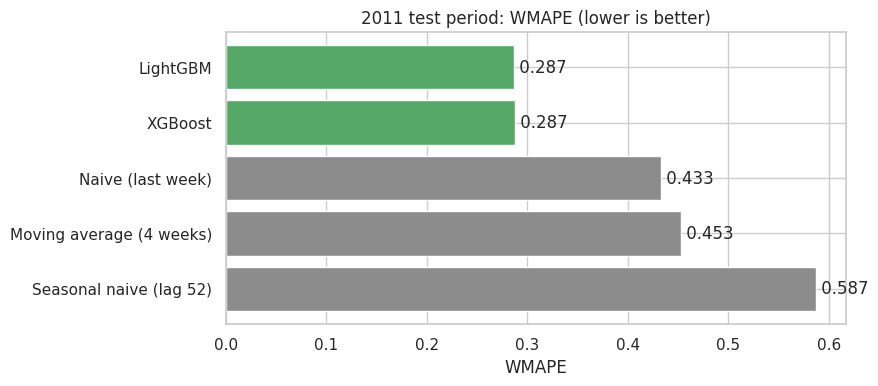

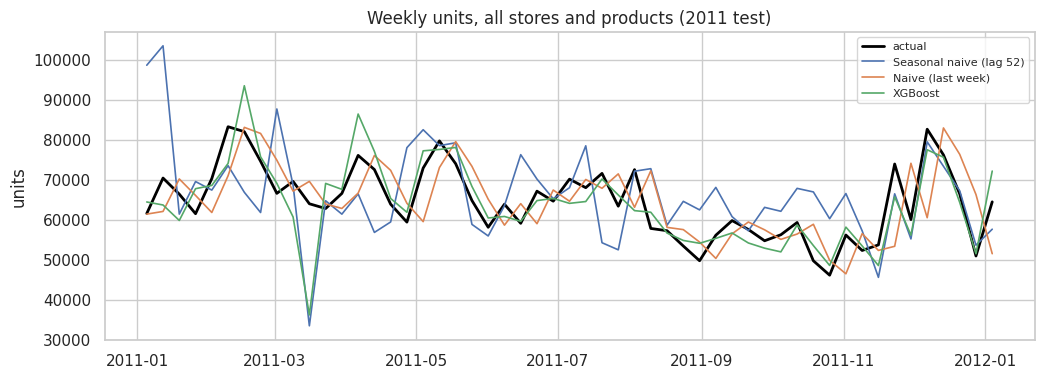

In [7]:
viz.model_comparison(table.drop(index=[i for i in table.index if "no bias" in i]), name=None); plt.show()
_, te = fc.train_test_masks(df)
viz.actual_vs_forecast(df.loc[te], {k: preds[k] for k in ["Seasonal naive (lag 52)", "Naive (last week)", "XGBoost"]}, name=None); plt.show()

**Reading the table**
* **Seasonal naive is the weakest model.** Demand here is driven by the promotion calendar, which changes from year to year, so "same week
  last year" is a poor guess. That is a data finding, not a bug.
* XGBoost and LightGBM cut WMAPE by roughly a third relative to the naive baseline. They achieve this because they know the planned price and promotion of the target week,
  which the baselines ignore.
* XGBoost and LightGBM are practically tied. XGBoost is kept as the primary model (per project brief). LightGBM confirms that the result is not specific to one library.
* **Retransformation bias.** Training on log1p gives a median-like forecast, so exp(E[log y]) < E[y] (Jensen's inequality) and total volume is
  under-forecast. The "no bias correction" rows show this. A single factor Σy/Σŷ from the last training fold removes most of it.
  During development a Poisson objective (`count:poisson`) was also tried: it was almost unbiased, but its WMAPE was slightly worse (see PROJECT_DECISIONS.md).

## 7. Interpretability with SHAP
SHAP values decompose each prediction (on the log1p scale) into additive feature contributions. They explain **what the model uses**.
They do **not** say what would happen if we changed a feature: that is a causal question (notebook 03).

In [8]:
import shap
X = df.loc[te, fe.feature_columns()].sample(3000, random_state=config.SEED)
sv = shap.TreeExplainer(models["XGBoost"])(X)
imp = pd.DataFrame({"feature": X.columns, "mean_abs_shap": np.abs(sv.values).mean(0)}).sort_values("mean_abs_shap", ascending=False)
imp.head(15)

,feature,mean_abs_shap
38,units_expanding_mean,0.3354
27,units_lag_1,0.2109
1,upc,0.0966
13,feature,0.0681
34,units_rollmean_4,0.0657
17,price_vs_recent_base,0.0605
36,units_rollmean_13,0.0603
0,store_num,0.0524
9,price,0.0440
14,display,0.0424


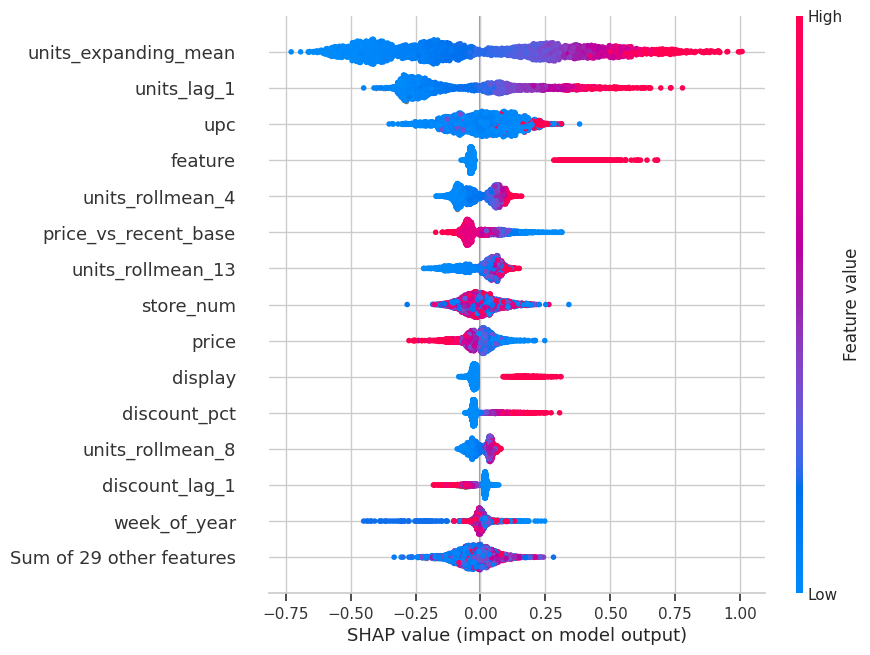

In [9]:
shap.plots.beeswarm(sv, max_display=15, show=False); plt.show()

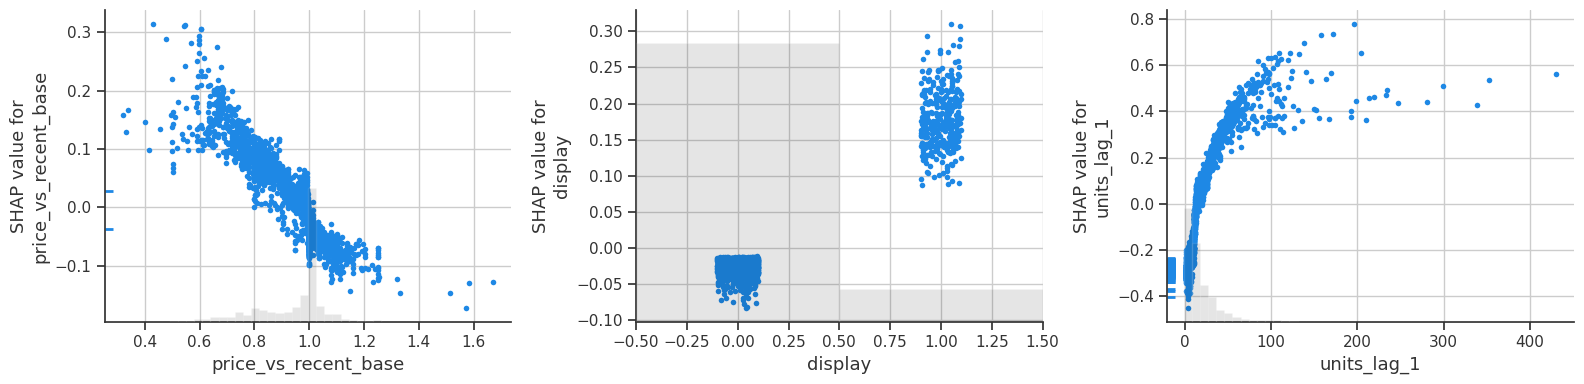

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f in zip(axes, ["price_vs_recent_base", "display", "units_lag_1"]):
    shap.plots.scatter(sv[:, f], ax=ax, show=False)
plt.tight_layout(); plt.show()

**What drives the forecast**
* **Demand-history features** (rolling means, lags, expanding mean) dominate. They encode the store-product's normal level.
* **Price relative to the recent regular price**: prices below the usual level push the prediction up, and higher prices push it down.
  This is the model's *associative* price effect, and it is learned mostly from promotional weeks.
* **Display / feature** add large positive contributions when switched on.
* **Lag 1** matters, but a high value last week after a promotion does not translate one-to-one into this week (post-promotion dip).

### Three example predictions

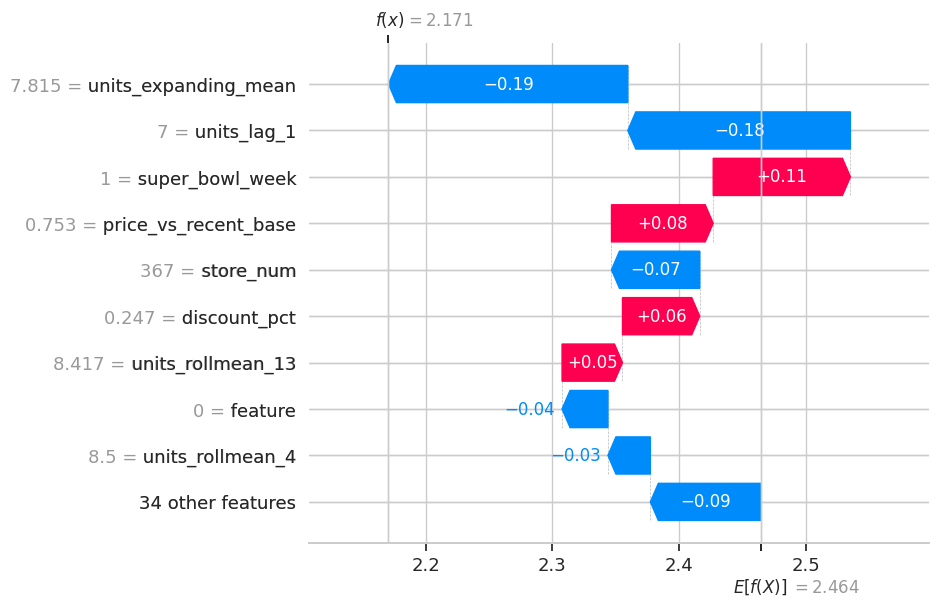

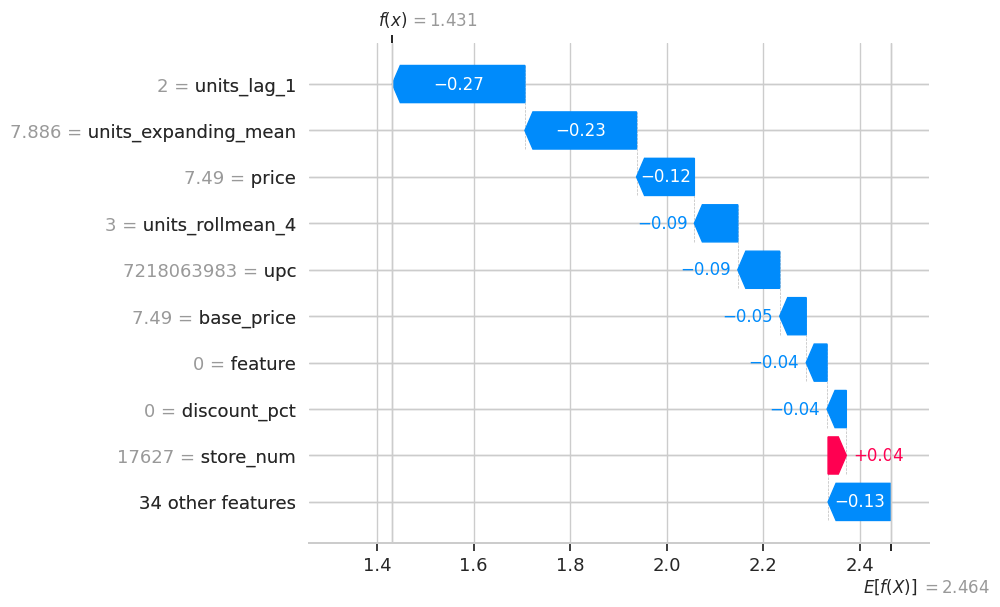

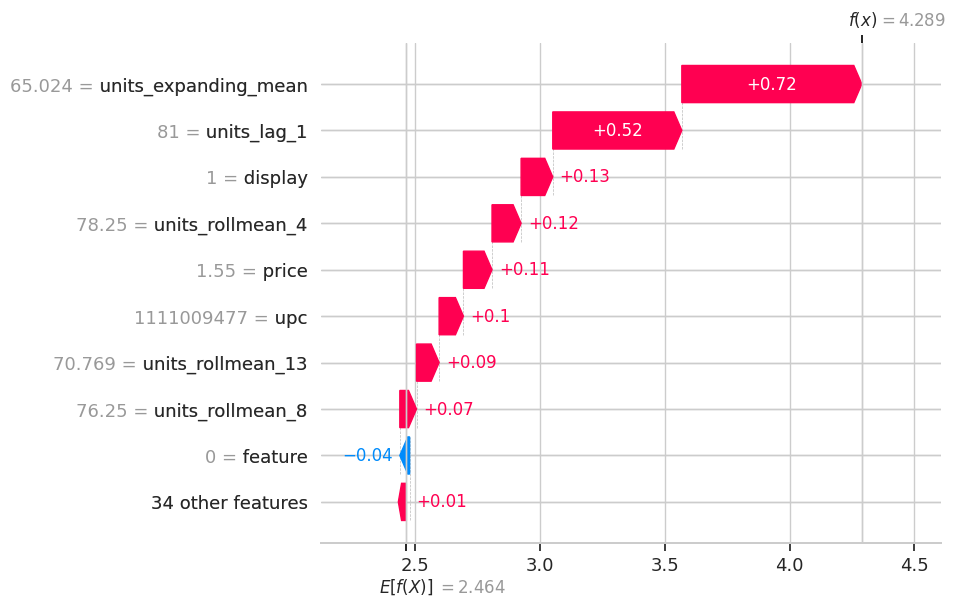

In [11]:
for i in [0, 1, 2]:
    shap.plots.waterfall(sv[i], max_display=10, show=False); plt.show()

## 8. Takeaways for pricing
1. The forecast is accurate enough to provide the baseline demand level `Q0` at the current price.
2. The model's price effect is **not** used as the elasticity for decisions. It is associative, learned mostly from short promotions, and
   not constrained to be monotone. Notebook 04 checks this directly.
3. Save the models (the pipeline does this: `models/xgb_train_only.json`, `models/xgb_production.json`).